# pycistopic PBMCs

the tutorial of pycistopic can be found here https://pycistopic.readthedocs.io/en/latest/index.html

**What are PBMCs?**

Peripheral blood mononuclear cells (PBMCs) are blood cells, in this case, cultured in tissue culture. They are used to study, for example, infectious diseases. 

workflow: 
1. import fragment files & consensus peaks
2. Quality Control (QC) analysis and cell selection
3. count matrix generation
4. topic modelling
5. dimensionality reduction & batch effect correction
6. downstream analysis (e.g. DARs, pseudobulk, ...)

In [8]:
# add pycisTopic to patth
import os
import pandas as pd
import pycisTopic
import pandas as pd
import pickle
import numpy as np
import tempfile

from pycisTopic.clust_vis import (
    find_clusters,
    run_umap,
    run_tsne,
    plot_metadata,
    plot_topic,
    cell_topic_heatmap
)

%matplotlib inline

# Add your env bin to PATH
os.environ["PATH"] += os.pathsep + "/data/teachers/software/miniforge3/envs/pycisTopic/bin"

pycisTopic.__version__

'2.0a0'

# 1. import fragment files 

check which files are all present for you as data in the data folder

In [2]:
pwd

'/data/user/u0154732'

In [3]:
!ls /data/teachers/data/scATAC/data_tutorial

CNA_10xv2_1.FULL.fragments.tsv.gz	    Merged__consensus_peaks.bed
CNA_10xv2_1.FULL.fragments.tsv.gz.tbi.html  metadata_pbmc_10x_v2.tsv
CNA_10xv2_2.FULL.fragments.tsv.gz	    rna_cell_types_annot.tsv.html
CNA_10xv2_2.FULL.fragments.tsv.gz.tbi.html  tss.bed
hg38-blacklist.v2.bed


find your own user name to give as out dir

In [41]:
!echo $USER

In [42]:
#check in which folder you are
!pwd

In [6]:
# make an output directory for this cistopic run
!mkdir -p cistopic_outs

In [6]:
out_dir = '/data/user/u0154732/cistopic_outs/' #adapt this to your own directory 


Import the fragment files into the notebook

In [10]:
#path to fragment files on teaching server, do not change
fragments_dict = {
    "CNA_10xv2_1": "/data/teachers/data/scATAC/data_tutorial/CNA_10xv2_1.FULL.fragments.tsv.gz",
    "CNA_10xv2_2": "/data/teachers/data/scATAC/data_tutorial/CNA_10xv2_2.FULL.fragments.tsv.gz"
}

In [11]:
#this part might be not needed if we give them the tss.be file
chromsizes = pd.read_table(
    "http://hgdownload.cse.ucsc.edu/goldenPath/hg38/bigZips/hg38.chrom.sizes",
    header = None,
    names = ["Chromosome", "End"]
)
chromsizes.insert(1, "Start", 0)
chromsizes.head()

,Chromosome,Start,End
0,chr1,0,248956422
1,chr2,0,242193529
2,chr3,0,198295559
3,chr4,0,190214555
4,chr5,0,181538259


In [12]:
!pycistopic tss gene_annotation_list --no-cache | grep Human

/data/teachers/software/miniforge3/envs/pycisTopic/lib/python3.11/site-packages/pycisTopic/__init__.py:3: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFound, get_distribution
hsapiens_gene_ensembl	Human genes (GRCh38.p14)


In [13]:
!mkdir -p cistopic_outs/QC

download the tss file into your folder (to know where the transcription start sites are in your data)

In [14]:
!pycistopic tss get_tss --no-cache \
    --output cistopic_outs/tss.bed \
    --name "hsapiens_gene_ensembl" \
    --to-chrom-source ucsc \
    --ucsc hg38

/data/teachers/software/miniforge3/envs/pycisTopic/lib/python3.11/site-packages/pycisTopic/__init__.py:3: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFound, get_distribution
- Get TSS annotation from Ensembl BioMart with the following settings:
  - biomart_name: "hsapiens_gene_ensembl"
  - biomart_host: "http://www.ensembl.org"
  - transcript_type: ['protein_coding']
  - use_cache: False
/data/teachers/software/miniforge3/envs/pycisTopic/lib/python3.11/site-packages/pybiomart/dataset.py:269: DtypeWarning: Columns (0) have mixed types. Specify dtype option on import or set low_memory=False.
  result = pd.read_csv(StringIO(response.text), sep='\t')
- Getting chromosome sizes and alias mapping for "hg38" from UCSC.
- Update chromosome names in TSS anno

In [15]:
!head cistopic_outs/tss.bed  #| column -t

# Chromosome	Start	End	Gene	Score	Strand	Transcript_type
chrM	3306	3307	MT-ND1	.	+	protein_coding
chrM	4469	4470	MT-ND2	.	+	protein_coding
chrM	5903	5904	MT-CO1	.	+	protein_coding
chrM	7585	7586	MT-CO2	.	+	protein_coding
chrM	8365	8366	MT-ATP8	.	+	protein_coding
chrM	8526	8527	MT-ATP6	.	+	protein_coding
chrM	9206	9207	MT-CO3	.	+	protein_coding
chrM	10058	10059	MT-ND3	.	+	protein_coding
chrM	10469	10470	MT-ND4L	.	+	protein_coding


In [16]:
regions_bed_filename = '/data/teachers/data/scATAC/data_tutorial/Merged__consensus_peaks.bed' #leave this like that (file on teaching server)
tss_bed_filename = '/data/teachers/data/scATAC/data_tutorial/tss.bed' #adapt this to your own tss.bed path

# 2. Quality Control and cell seletcion

In [17]:
pycistopic_qc_commands_filename = "pycistopic_qc_commands.txt"

# Create text file with all pycistopic qc command lines.
with open(pycistopic_qc_commands_filename, "w") as fh:
    print("#!/usr/bin/bash", file=fh)
    for sample, fragment_filename in fragments_dict.items():
        print(
            "pycistopic qc",
            f"--fragments {fragment_filename}",
            f"--regions {regions_bed_filename}",
            f"--tss {tss_bed_filename}",
            f"--output {os.path.join(out_dir, 'QC')}/{sample}",
            sep=" ",
            file=fh,
        )

Now you have created a text file, look at it in jupyter notebook and check that all paths are existing. 


Then run the QC in an command line environment. For this, open a terminal on the teaching server, go to the foler where your jupyternotbooks and, thus, pycistopic_qc_commands.txt are (likel data/jupyternotebooks) and run the folling command. This should take up to 10 minutes. You can already see the QC log file for your samples appear in the out_dir/QC folder.

In [18]:
!chmod +x pycistopic_qc_commands.txt
!./pycistopic_qc_commands.txt

/data/teachers/software/miniforge3/envs/pycisTopic/lib/python3.11/site-packages/pycisTopic/__init__.py:3: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFound, get_distribution
/data/teachers/software/miniforge3/envs/pycisTopic/lib/python3.11/site-packages/pycisTopic/genomic_ranges.py:354: PerformanceWarning: Determining the column names of a LazyFrame requires resolving its schema, which is a potentially expensive operation. Use `LazyFrame.collect_schema().names()` to get the column names without this warning.
  for column_name in df.columns
/data/teachers/software/miniforge3/envs/pycisTopic/lib/python3.11/site-packages/pycisTopic/genomic_ranges.py:369: PerformanceWarning: Determining the column names of a LazyFrame requires resolving its schema, whic

when it finished, we can continue plotting the statistics. You should have the following files in that folder:

In [19]:
!ls /mnt/storage/data/teaching_regenomics/QC

ls: cannot access '/mnt/storage/data/teaching_regenomics/QC': No such file or directory


In [20]:
from pycisTopic.plotting.qc_plot import plot_sample_stats, plot_barcode_stats
import matplotlib.pyplot as plt

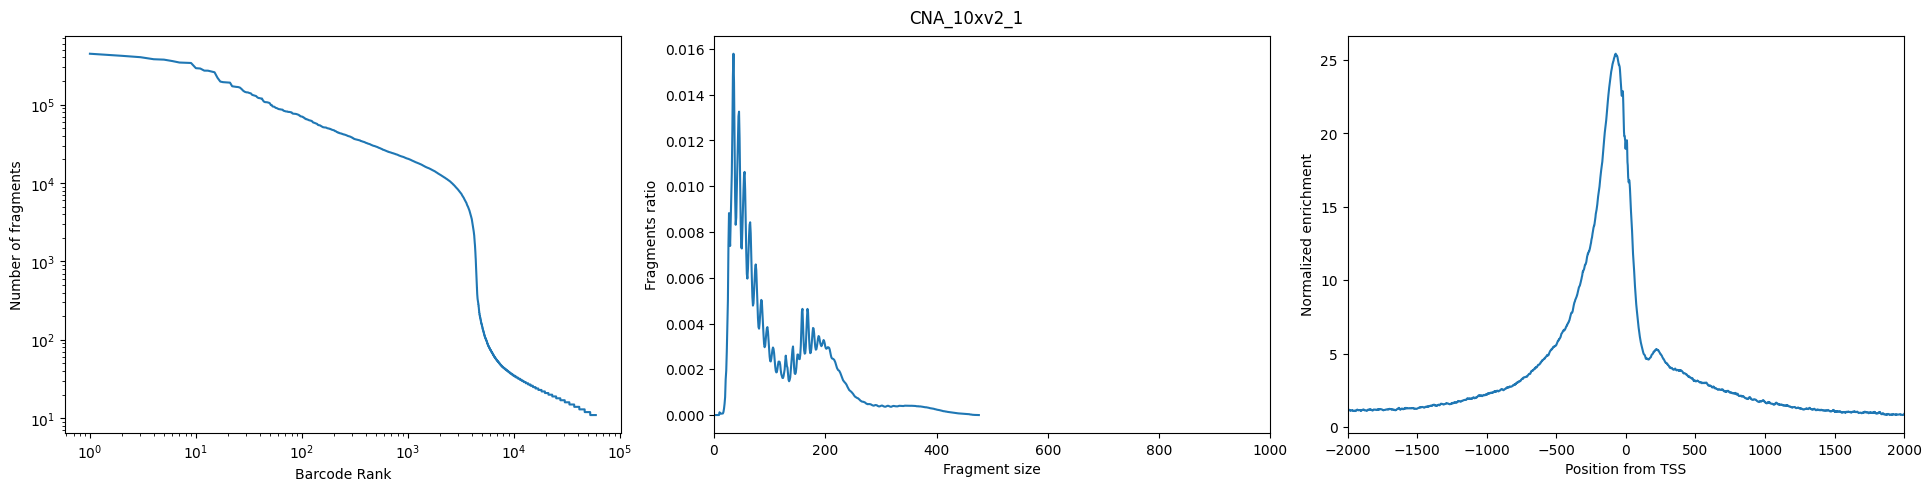

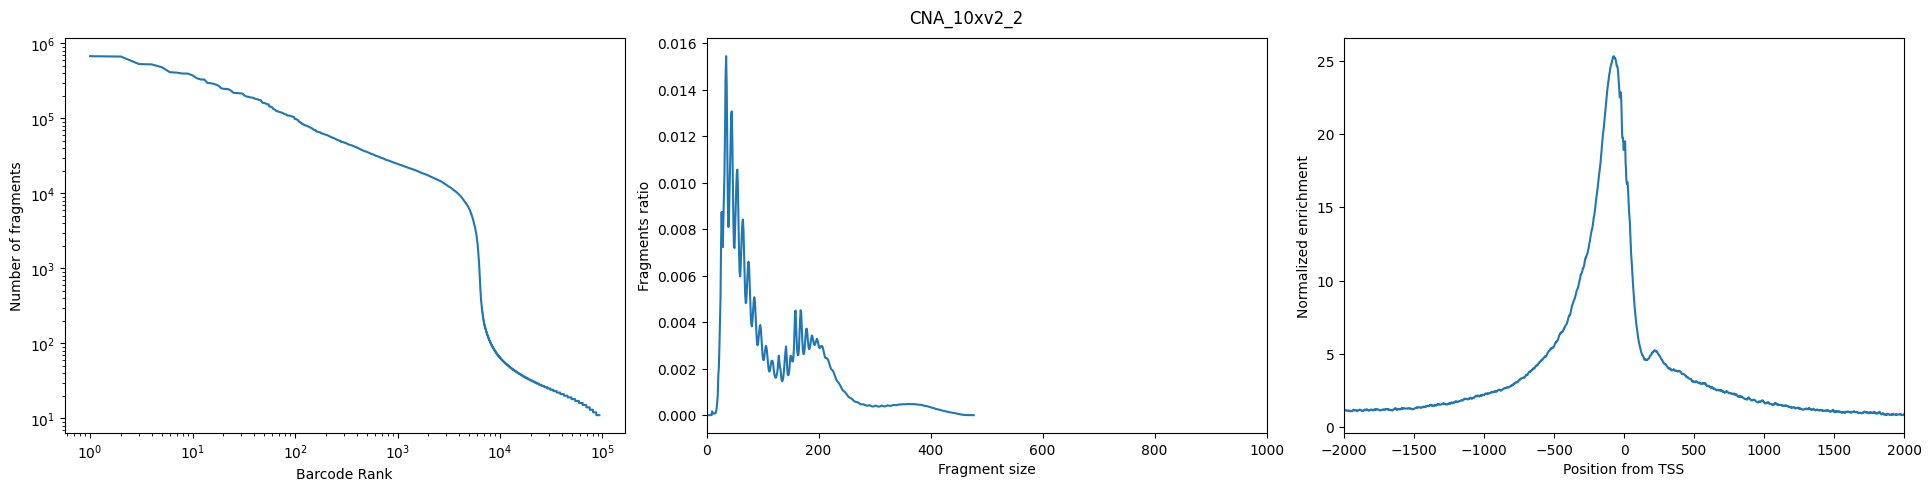

In [21]:
for sample_id in fragments_dict:
    fig = plot_sample_stats(
        sample_id = sample_id,
        pycistopic_qc_output_dir = "cistopic_outs/QC" #if the command before took too long, change the path to "/mnt/storage/data/teaching_regenomics/QC"
    )

In [22]:
from pycisTopic.qc import get_barcodes_passing_qc_for_sample
sample_id_to_barcodes_passing_filters = {}
sample_id_to_thresholds = {}
for sample_id in fragments_dict:
    (
        sample_id_to_barcodes_passing_filters[sample_id],
        sample_id_to_thresholds[sample_id]
    ) = get_barcodes_passing_qc_for_sample(
            sample_id = sample_id,
            pycistopic_qc_output_dir = "cistopic_outs/QC",
            unique_fragments_threshold = None, # use automatic thresholding
            tss_enrichment_threshold = None, # use automatic thresholding
            frip_threshold = 0,
            use_automatic_thresholds = True,
    )

CNA_10xv2_1:
	Using automatic threshold for unique fragments: 1564.932380646473
	Using automatic threshold for TSS enrichment: 12.365964356435644
CNA_10xv2_2:
	Using automatic threshold for unique fragments: 1714.633542879881
	Using automatic threshold for TSS enrichment: 12.326688501202387


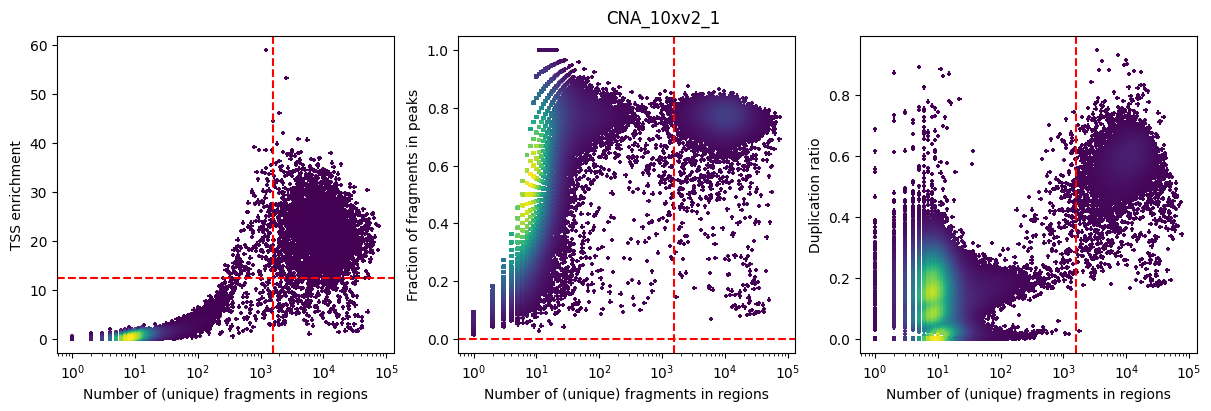

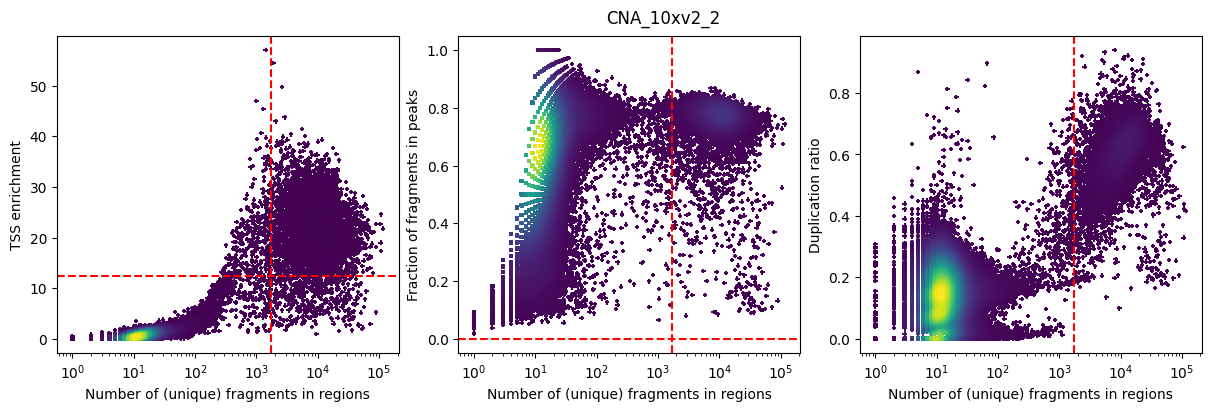

In [23]:
for sample_id in fragments_dict:
    fig = plot_barcode_stats(
        sample_id = sample_id,
        pycistopic_qc_output_dir = "cistopic_outs/QC",
        bc_passing_filters = sample_id_to_barcodes_passing_filters[sample_id],
        detailed_title = False,
        **sample_id_to_thresholds[sample_id]
    )

We see a cloud of high quality cells in the opper right corner that is seperate from the others. However, we can still lower the TSS enrichment and Number of (unique) frgaments a little bit to include more cells. So we run the QC selection again as follows:

In [24]:
from pycisTopic.qc import get_barcodes_passing_qc_for_sample
sample_id_to_barcodes_passing_filters = {}
sample_id_to_thresholds = {}
for sample_id in fragments_dict:
    (
        sample_id_to_barcodes_passing_filters[sample_id],
        sample_id_to_thresholds[sample_id]
    ) = get_barcodes_passing_qc_for_sample(
            sample_id = sample_id,
            pycistopic_qc_output_dir = "cistopic_outs/QC",
            unique_fragments_threshold = 1000, # use automatic thresholding
            tss_enrichment_threshold = 10, # use automatic thresholding
            frip_threshold = 0,
            use_automatic_thresholds = True,
    )

CNA_10xv2_1:
	Using user-defined threshold for unique fragments: 1000
	Using user-defined threshold for TSS enrichment: 10
CNA_10xv2_2:
	Using user-defined threshold for unique fragments: 1000
	Using user-defined threshold for TSS enrichment: 10


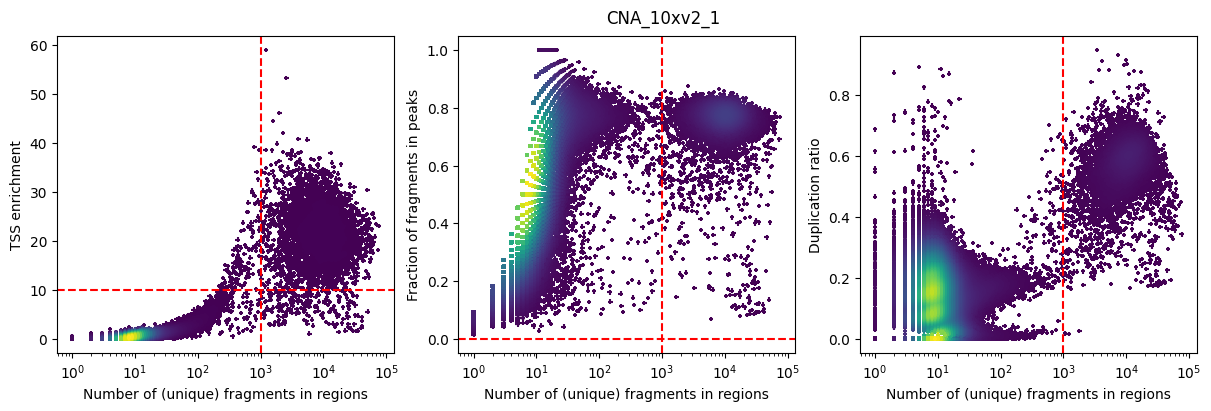

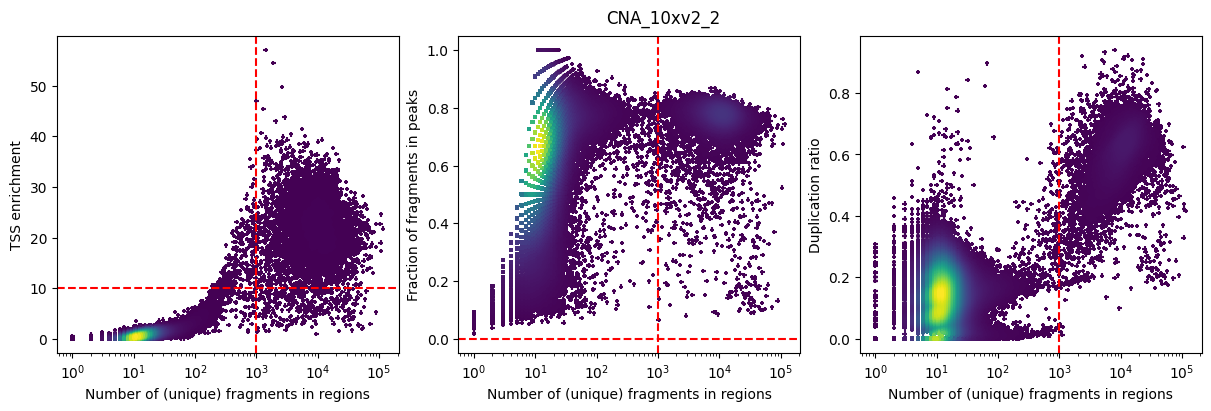

In [25]:
for sample_id in fragments_dict:
    fig = plot_barcode_stats(
        sample_id = sample_id,
        pycistopic_qc_output_dir = "cistopic_outs/QC",
        bc_passing_filters = sample_id_to_barcodes_passing_filters[sample_id],
        detailed_title = False,
        **sample_id_to_thresholds[sample_id]
    )

# 3. Count matrix generation

In [26]:
# change to your folders - or leave to the teaching one
path_to_regions = ("/data/teachers/data/scATAC/data_tutorial/Merged__consensus_peaks.bed")
path_to_blacklist = "/data/teachers/data/scATAC/data_tutorial/hg38-blacklist.v2.bed"
pycistopic_qc_output_dir = "cistopic_outs/QC"

Next, we make a list of cistopic objects per sample. On 1 CPU this should take max 10 minutes.

In [27]:
from pycisTopic.cistopic_class import create_cistopic_object_from_fragments
import polars as pl

cistopic_obj_list = []
for sample_id in fragments_dict:
    sample_metrics = pl.read_parquet(
        os.path.join(pycistopic_qc_output_dir, f'{sample_id}.fragments_stats_per_cb.parquet')
    ).to_pandas().set_index("CB").loc[ sample_id_to_barcodes_passing_filters[sample_id] ]
    cistopic_obj = create_cistopic_object_from_fragments(
        path_to_fragments = fragments_dict[sample_id],
        path_to_regions = path_to_regions,
        path_to_blacklist = path_to_blacklist,
        metrics = sample_metrics,
        valid_bc = sample_id_to_barcodes_passing_filters[sample_id],
        n_cpu = 2,
        project = sample_id,
        split_pattern = '-'
    )
    cistopic_obj_list.append(cistopic_obj)

2025-10-27 09:14:42,658 cisTopic     INFO     Reading data for CNA_10xv2_1
2025-10-27 09:15:35,670 cisTopic     INFO     metrics provided!
2025-10-27 09:15:38,093 cisTopic     INFO     Counting fragments in regions


2025-10-27 09:15:38,910	INFO util.py:154 -- Missing packages: ['ipywidgets']. Run `pip install -U ipywidgets`, then restart the notebook server for rich notebook output.
2025-10-27 09:15:44,029	INFO worker.py:1724 -- Started a local Ray instance.
(pid=3062587) /data/teachers/software/miniforge3/envs/pycisTopic/lib/python3.11/site-packages/pyranges/__init__.py:18: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
(pid=3062587)   import pkg_resources
(pid=3062586) /data/teachers/software/miniforge3/envs/pycisTopic/lib/python3.11/site-packages/pyranges/__init__.py:18: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptool

2025-10-27 09:16:06,988 cisTopic     INFO     Creating fragment matrix
2025-10-27 09:16:30,348 cisTopic     INFO     Converting fragment matrix to sparse matrix
2025-10-27 09:16:35,588 cisTopic     INFO     Removing blacklisted regions
2025-10-27 09:16:36,268 cisTopic     INFO     Creating CistopicObject
2025-10-27 09:16:37,213 cisTopic     INFO     Done!
2025-10-27 09:16:37,464 cisTopic     INFO     Reading data for CNA_10xv2_2
2025-10-27 09:17:53,068 cisTopic     INFO     metrics provided!
2025-10-27 09:17:56,629 cisTopic     INFO     Counting fragments in regions


2025-10-27 09:18:03,337	INFO worker.py:1724 -- Started a local Ray instance.
(pid=3064830) /data/teachers/software/miniforge3/envs/pycisTopic/lib/python3.11/site-packages/pyranges/__init__.py:18: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
(pid=3064830)   import pkg_resources
(pid=3064831) /data/teachers/software/miniforge3/envs/pycisTopic/lib/python3.11/site-packages/pyranges/__init__.py:18: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
(pid=3064831)   import pkg_resources


2025-10-27 09:18:34,152 cisTopic     INFO     Creating fragment matrix
2025-10-27 09:19:31,930 cisTopic     INFO     Converting fragment matrix to sparse matrix
2025-10-27 09:19:44,120 cisTopic     INFO     Removing blacklisted regions
2025-10-27 09:19:44,734 cisTopic     INFO     Creating CistopicObject
2025-10-27 09:19:48,221 cisTopic     INFO     Done!


Now you have a list of two cistopic objects. To merge then you run the following command. 

In [28]:
from pycisTopic.cistopic_class import *
cistopic_obj = merge(cistopic_obj_list)
print(cistopic_obj)

2025-10-27 09:19:53,608 cisTopic     INFO     cisTopic object 1 merged
CistopicObject from project cisTopic_merge with n_cells × n_regions = 9914 × 327962


Your merged cistopic object should have 9,911 cells and 327,962 accessible regions.

In [29]:
# in cell_data, the matrix is stored: 
cistopic_obj.cell_data

,cisTopic_nr_frag,cisTopic_log_nr_frag,cisTopic_nr_acc,cisTopic_log_nr_acc,sample_id,barcode_rank,total_fragments_count,log10_total_fragments_count,unique_fragments_count,log10_unique_fragments_count,...,log10_unique_fragments_in_peaks_count,fraction_of_fragments_in_peaks,duplication_count,duplication_ratio,nucleosome_signal,tss_enrichment,pdf_values_for_tss_enrichment,pdf_values_for_fraction_of_fragments_in_peaks,pdf_values_for_duplication_ratio,barcode
GTATAGCTGGACACCC-CNA_10xv2_1___CNA_10xv2_1,16664,4.221779,13523,4.131073,CNA_10xv2_1,879,52102,4.716863,21780,4.338078,...,4.217484,0.757530,30322,0.581974,0.399101,14.988045,0.002986,0.464726,0.347629,GTATAGCTGGACACCC
CGATCAAACTCTGTGA-CNA_10xv2_1___CNA_10xv2_1,11720,4.068928,9171,3.962417,CNA_10xv2_1,1611,32627,4.513590,15264,4.183697,...,4.064046,0.759172,17363,0.532167,0.272195,19.378578,0.005757,0.607594,0.279188,CGATCAAACTCTGTGA
CGCACTTACCAATAGA-CNA_10xv2_1___CNA_10xv2_1,11443,4.05854,9769,3.98985,CNA_10xv2_1,1775,24128,4.382539,14247,4.153754,...,4.053731,0.794272,9881,0.409524,0.337660,18.155290,0.004606,0.594588,0.036925,CGCACTTACCAATAGA
GTTCCCATGACCGTGC-CNA_10xv2_1___CNA_10xv2_1,19315,4.285895,12815,4.107719,CNA_10xv2_1,709,73866,4.868450,24277,4.385213,...,4.280715,0.786135,49589,0.671337,0.315032,28.813296,0.001465,0.401221,0.197593,GTTCCCATGACCGTGC
CTGCACGGATGTCACA-CNA_10xv2_1___CNA_10xv2_1,10646,4.027186,9242,3.965766,CNA_10xv2_1,1883,26411,4.421801,13573,4.132708,...,4.023211,0.777131,12838,0.486085,0.322734,17.049868,0.004214,0.656391,0.146587,CTGCACGGATGTCACA
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ATCGCAAACCTACTCC-CNA_10xv2_2___CNA_10xv2_2,1317,3.119586,1173,3.069298,CNA_10xv2_2,6056,5064,3.704579,2027,3.307068,...,3.116940,0.645289,3037,0.599724,0.341944,20.655151,0.000406,0.023312,0.014657,ATCGCAAACCTACTCC
TGGTAGGGAGAACCTT-CNA_10xv2_2___CNA_10xv2_2,1151,3.061075,963,2.983626,CNA_10xv2_2,5955,8504,3.929674,2440,3.387568,...,3.057286,0.467213,6064,0.713076,0.548128,22.887597,0.000371,0.006090,0.004271,TGGTAGGGAGAACCTT
ATACCTGGAGTCCCGA-CNA_10xv2_2___CNA_10xv2_2,10305,4.013048,6935,3.841046,CNA_10xv2_2,1042,89397,4.951328,24305,4.385713,...,4.007107,0.418186,65092,0.728123,0.838012,21.997656,0.005947,0.005912,0.127616,ATACCTGGAGTCCCGA
CCACTCTGAAGGCGTA-CNA_10xv2_2___CNA_10xv2_2,8324,3.920332,6080,3.783904,CNA_10xv2_2,837,61096,4.786020,27060,4.432344,...,3.913231,0.302587,34036,0.557090,1.209335,15.228458,0.001994,0.001806,0.311839,CCACTCTGAAGGCGTA


In [30]:
# let's save the cistopic obj
import pickle
pickle.dump(
    cistopic_obj,
    open(os.path.join(out_dir, "cistopic_obj.pkl"), "wb")
)

## Scrublet

With Scrublet we can remove doublets from the sample. If you have a high quality sample, this is not necessary or you will only remove very little cells. Let's have a look how this looks like for our sample. Running scrublet takes 3 minutes.

Preprocessing...
Simulating doublets...
Embedding transcriptomes using PCA...
Calculating doublet scores...
Automatically set threshold at doublet score = 0.17
Detected doublet rate = 19.3%
Estimated detectable doublet fraction = 72.7%
Overall doublet rate:
	Expected   = 10.0%
	Estimated  = 26.6%
Elapsed time: 54.6 seconds
Detected doublet rate = 12.5%
Estimated detectable doublet fraction = 61.3%
Overall doublet rate:
	Expected   = 10.0%
	Estimated  = 20.4%


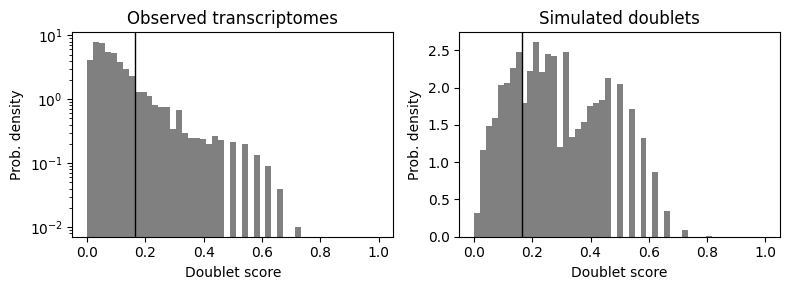

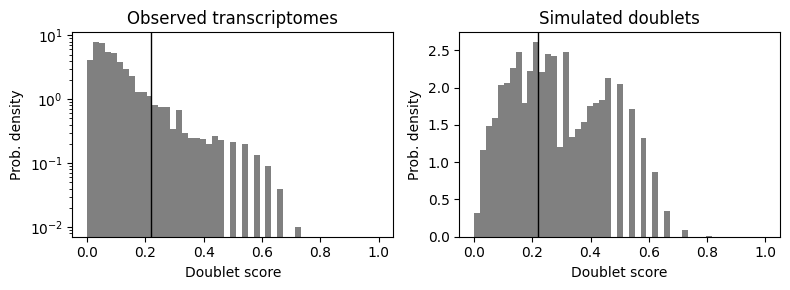

In [31]:
import scrublet as scr
scrub = scr.Scrublet(cistopic_obj.fragment_matrix.T, expected_doublet_rate=0.1)
doublet_scores, predicted_doublets = scrub.scrub_doublets()
scrub.plot_histogram();
scrub.call_doublets(threshold=0.22)
scrub.plot_histogram();
scrublet = pd.DataFrame([scrub.doublet_scores_obs_, scrub.predicted_doublets_], columns=cistopic_obj.cell_names, index=['Doublet_scores_fragments', 'Predicted_doublets_fragments']).T

In [32]:
cistopic_obj.add_cell_data(scrublet, split_pattern = '-')
sum(cistopic_obj.cell_data.Predicted_doublets_fragments == True)

1239

We have 1242 cells that are predicted to be doublets, let's remove them.

In [33]:
# Remove doublets
singlets = cistopic_obj.cell_data[cistopic_obj.cell_data.Predicted_doublets_fragments == False].index.tolist()
# Subset cisTopic object
cistopic_obj_noDBL = cistopic_obj.subset(singlets, copy=True, split_pattern='-')
print(cistopic_obj_noDBL)

CistopicObject from project cisTopic_merge with n_cells × n_regions = 8675 × 327948


Our new cistopic object has 8,672 cells without the doublets. Now we save the cleaned object and continue with the topic modelling.

In [34]:
pickle.dump(
    cistopic_obj_noDBL,
    open(os.path.join(out_dir, "cistopic_obj_noDBL.pkl"), "wb")
)

In [35]:
# if you have to load the cistopic_obj again, you can do it like this: 
import pickle
infile = open(out_dir + 'cistopic_obj_noDBL.pkl', 'rb')
cistopic_obj_noDBL = pickle.load(infile)
infile.close()

# 4. Topic modelling

We can run the topic modeling as a job or run directly here in in the notebook. As this might both take some time, you can run a model with 2 topics here and we provide additional topic models in the next session.

First you need to download Mallet. Open the terminal and run the two bash commands below (does not work in this kernel)

In [36]:
!mkdir -p cistopic_outs/tmp
!mkdir -p cistopic_outs/models

Now we can run the script for the topic modeling, this might take up to 30 minutes for one topic model of 2 topics. You can do this at home if you like. 

In [46]:
os.environ['MALLET_MEMORY'] = '200G'
from pycisTopic.lda_models import run_cgs_models_mallet
# Configure path Mallet
mallet_path="/data/user/u0154732/Mallet-202108/bin/mallet" #adapt this to your own path where you saved the Mallet folder
# Run models
models=run_cgs_models_mallet(
    cistopic_obj_noDBL,
    n_topics=[30,35,40],
    n_cpu=20,
    n_iter=500,
    random_state=555,
    alpha=50,
    alpha_by_topic=True,
    eta=0.1,
    eta_by_topic=False,
    tmp_path= out_dir+"tmp",
    save_path=out_dir+"models",
    mallet_path=mallet_path,
)

2025-10-27 09:44:41,643 cisTopic     INFO     Formatting input to corpus
2025-10-27 09:44:43,925 cisTopic     INFO     Running model with 30 topics
2025-10-27 09:44:43,926 LDAMalletWrapper INFO     Serializing temporary corpus to /data/user/u0154732/cistopic_outs/tmp/corpus.txt
2025-10-27 09:45:02,753 LDAMalletWrapper INFO     Converting temporary corpus to MALLET format with: /data/user/u0154732/Mallet-202108/bin/mallet import-file --preserve-case --keep-sequence --token-regex \S+ --input /data/user/u0154732/cistopic_outs/tmp/corpus.txt --output /data/user/u0154732/cistopic_outs/tmp/corpus.mallet
2025-10-27 09:45:47,328 LDAMalletWrapper INFO     Training MALLET LDA with: /data/user/u0154732/Mallet-202108/bin/mallet train-topics --input /data/user/u0154732/cistopic_outs/tmp/corpus.mallet --num-topics 30 --alpha 50 --beta 0.1 --optimize-interval 0 --num-threads 20 --output-state /data/user/u0154732/cistopic_outs/tmp/21922a_state.mallet.gz --output-doc-topics /data/user/u0154732/cistopic

In [47]:
pickle.dump(
    models,
    open(os.path.join(out_dir, "models/models.pkl"), "wb")
)

## Model selection

In [4]:
# we import the cistopic obj (without doublet) on which we also did the topic modeling.
import pickle
infile = open('/data/teachers/data/scATAC/data_tutorial/cistopic_obj_noDBL.pkl', 'rb')
cistopic_obj = pickle.load(infile)
infile.close()

/data/teachers/software/miniforge3/envs/pycisTopic/lib/python3.11/site-packages/pycisTopic/__init__.py:3: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFound, get_distribution


In [5]:
with open("/data/teachers/data/scATAC/data_tutorial/models.pkl", "rb") as f:
    models = pickle.load(f)
# or change to your own models.pkl file

/data/teachers/software/miniforge3/envs/pycisTopic/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2025-11-03 15:25:16,125	INFO util.py:154 -- Missing packages: ['ipywidgets']. Run `pip install -U ipywidgets`, then restart the notebook server for rich notebook output.


For scATAC-seq data models, the most helpful methods are Minmo (topic coherence) and the log-likelihood in the last iteration.  
Empirical rule-of-thumb: number of topics ~ expected number of cell states in the data. 

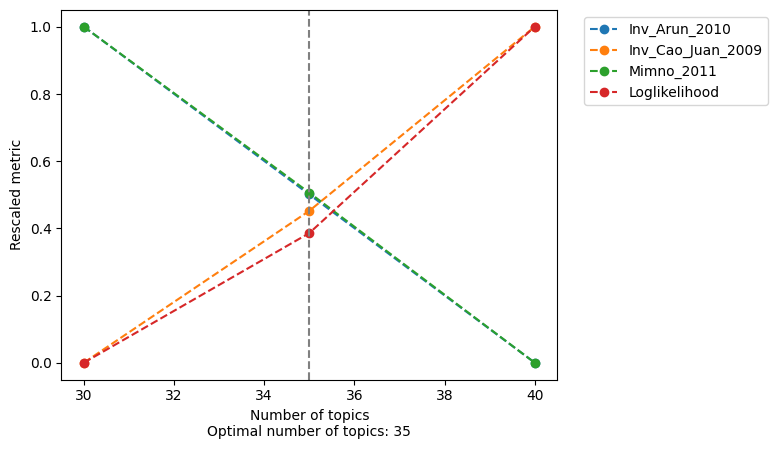

In [6]:
from pycisTopic.lda_models import evaluate_models
model = evaluate_models(
    models,
    select_model = 35,
    return_model = True
)

We select the model with 35 topics and add it to our cistopic object.

In [7]:
cistopic_obj.add_LDA_model(model)

# 5. Clustering and data visualization

In [10]:
from pycisTopic.clust_vis import (
    find_clusters,
    run_umap,
    run_tsne,
    plot_metadata,
    plot_topic,
    cell_topic_heatmap
)

Now we can run the clustering to look at the data as tSNE or UMAP embedding. Calculating the UMAP and tSNE will take a few minutes.

In [11]:
find_clusters(
    cistopic_obj,
    target  = 'cell',
    k = 10,
    res = [0.6, 1.2, 3],
    prefix = 'pycisTopic_',
    scale = True,
    split_pattern = '-'
)


2025-11-03 15:47:22,569 cisTopic     INFO     Finding neighbours
Columns ['pycisTopic_leiden_10_0.6'] will be overwritten
Columns ['pycisTopic_leiden_10_1.2'] will be overwritten
Columns ['pycisTopic_leiden_10_3'] will be overwritten


In [12]:
run_umap(
    cistopic_obj,
    target  = 'cell', 
    scale=True)

2025-11-03 15:47:30,463 cisTopic     INFO     Running UMAP


/data/teachers/software/miniforge3/envs/pycisTopic/lib/python3.11/site-packages/umap/umap_.py:1943: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")


In [13]:
run_tsne(
    cistopic_obj,
    target  = 'cell', 
    scale=True)

2025-11-03 15:47:49,361 cisTopic     INFO     Running TSNE


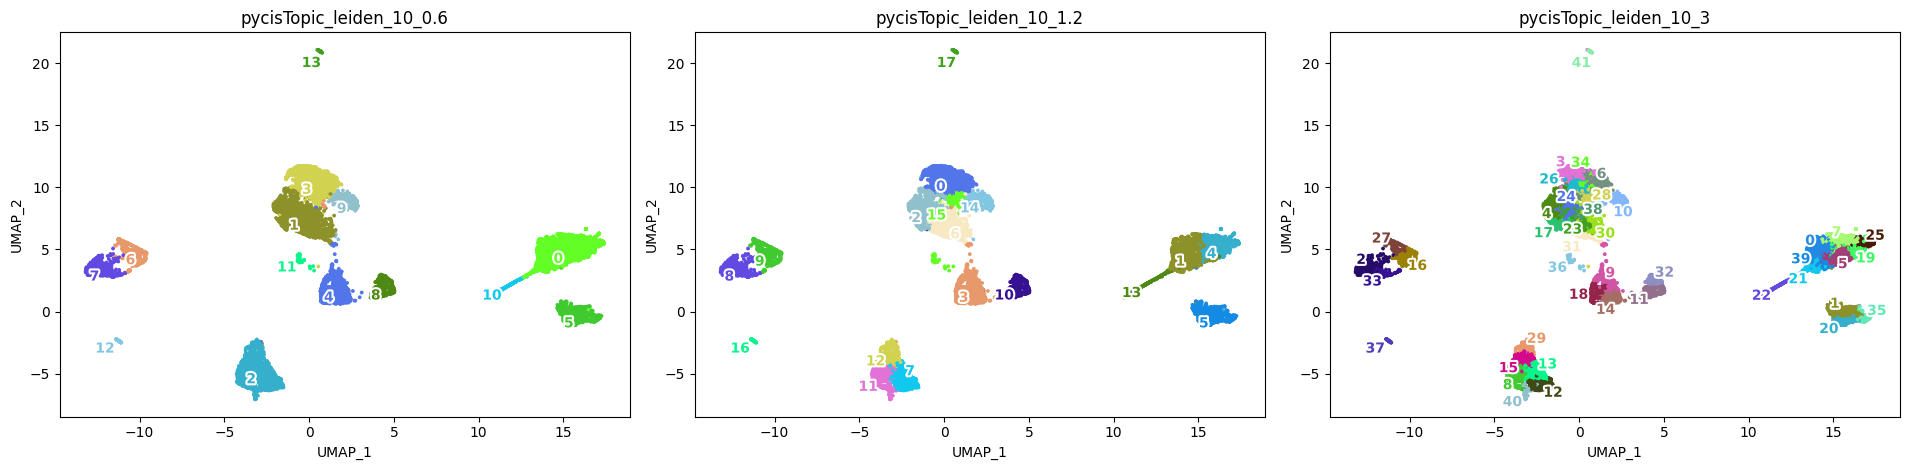

In [14]:
plot_metadata(
    cistopic_obj,
    reduction_name='UMAP',
    variables=['pycisTopic_leiden_10_0.6', 'pycisTopic_leiden_10_1.2', 'pycisTopic_leiden_10_3'],
    target='cell', num_columns=3,
    text_size=10,
    dot_size=3)

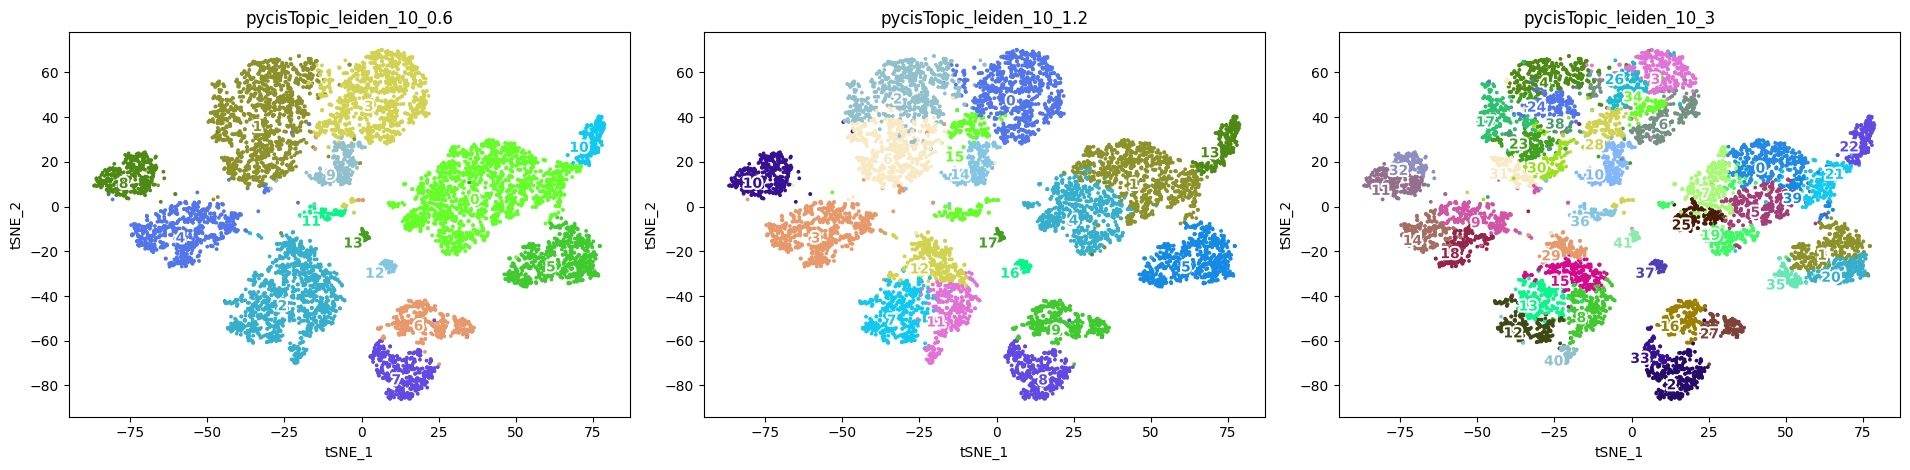

In [15]:
plot_metadata(
    cistopic_obj,
    reduction_name='tSNE',
    variables=['pycisTopic_leiden_10_0.6', 'pycisTopic_leiden_10_1.2', 'pycisTopic_leiden_10_3'],
    target='cell', num_columns=3,
    text_size=10,
    dot_size=3)

In [18]:
pickle.dump(
    cistopic_obj,
    open(os.path.join(out_dir, "cistopic_obj_noDBL_models.pkl"), "wb")
)

### Let's inspect some QC statistics of the dataset

Let's plot some QC paramters on the UMAP. You can see which parameters you can plot by running `cistopic_obj.cell_data.columns`

In [16]:
cistopic_obj.cell_data.columns

Index(['pdf_values_for_tss_enrichment', 'duplication_ratio', 'cisTopic_nr_acc',
       'log10_total_fragments_count', 'pdf_values_for_duplication_ratio',
       'cisTopic_nr_frag', 'cisTopic_log_nr_acc', 'pycisTopic_leiden_10_0.6',
       'barcode', 'nucleosome_signal', 'log10_unique_fragments_in_peaks_count',
       'Predicted_doublets_fragments', 'total_fragments_in_peaks_count',
       'unique_fragments_count', 'cisTopic_log_nr_frag', 'barcode_rank',
       'Doublet_scores_fragments', 'pycisTopic_leiden_10_1.2',
       'log10_total_fragments_in_peaks_count',
       'pdf_values_for_fraction_of_fragments_in_peaks', 'sample_id',
       'unique_fragments_in_peaks_count', 'duplication_count',
       'tss_enrichment', 'fraction_of_fragments_in_peaks',
       'total_fragments_count', 'log10_unique_fragments_count',
       'pycisTopic_leiden_10_3'],
      dtype='object')

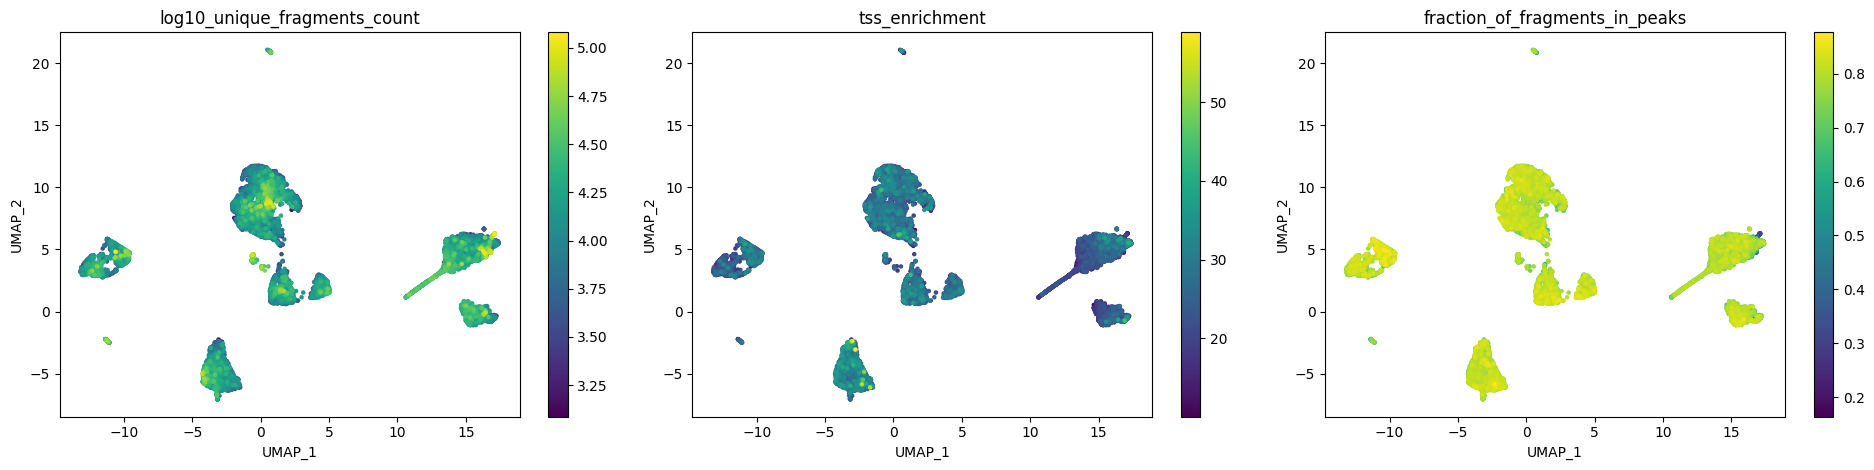

In [17]:
plot_metadata(
    cistopic_obj,
    reduction_name='UMAP', # or reduction_name='tSNE' 
    variables=['log10_unique_fragments_count', 'tss_enrichment', 'fraction_of_fragments_in_peaks'],
    target='cell', num_columns=3,
    text_size=10,
    dot_size=5)

### Finally, let's add cell type annotations (trasferred from scRNA in the original publication [De Rop et al 2024])

In [21]:
!ls /data/teachers/data/scATAC/data_tutorial/

CNA_10xv2_1.FULL.fragments.tsv.gz	    Merged__consensus_peaks.bed
CNA_10xv2_1.FULL.fragments.tsv.gz.tbi.html  metadata_pbmc_10x_v2.tsv
CNA_10xv2_2.FULL.fragments.tsv.gz	    models.pkl
CNA_10xv2_2.FULL.fragments.tsv.gz.tbi.html  rna_cell_types_annot.tsv.html
hg38-blacklist.v2.bed			    tss.bed


In [24]:
rna_cell_types = pd.read_csv("/data/teachers/data/scATAC/data_tutorial/rna_cell_types_annot.tsv", sep = "\t", low_memory=False).set_index("barcode")
rna_cell_types.head() 

,consensus_cell_type
barcode,
AAACAACGAAAGCTAA-CNA_10xv2_1,CD4+ T cell
AAACAACGAAGACAAT-CNA_10xv2_1,CD4+ T cell
AAACAACGAAGCCATT-CNA_10xv2_1,CD4+ T cell
AAACAACGAAGGCATG-CNA_10xv2_1,CD14+ monocyte
AAACAACGAAGGTGAC-CNA_10xv2_1,CD16+ monocyte


based on the barcode we now add the rna labels to our data.

In [25]:
cistopic_obj.add_cell_data(rna_cell_types)

### Now we plot the cell types and check if they match with our Leiden clustering 

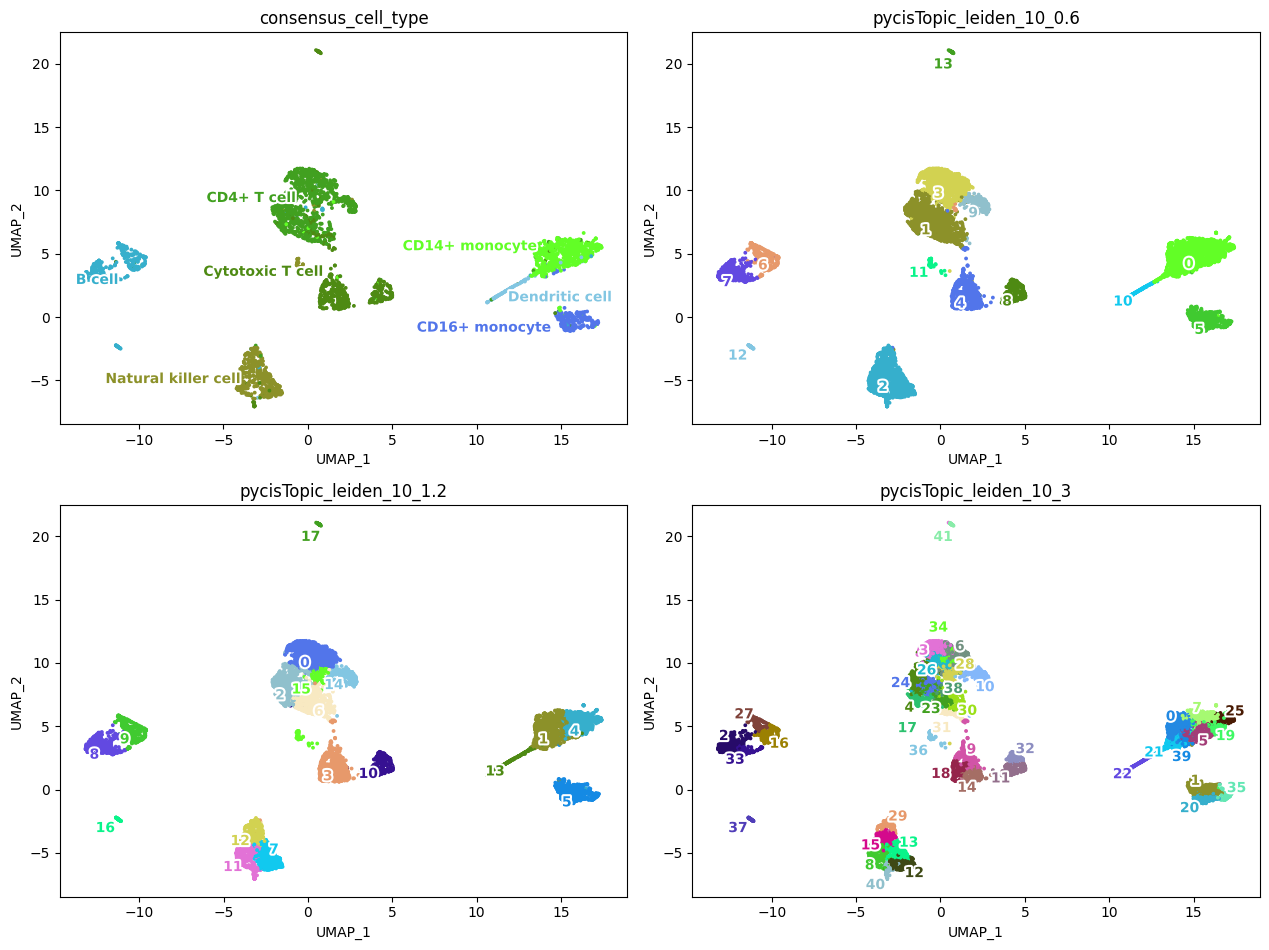

In [26]:
plot_metadata(
    cistopic_obj,
    reduction_name='UMAP',
    variables=['consensus_cell_type', 'pycisTopic_leiden_10_0.6', 'pycisTopic_leiden_10_1.2', 'pycisTopic_leiden_10_3'],
    target='cell', 
    num_columns=2,
    text_size=10,
    dot_size=3)

When we count now the annotations, we see that some cells are not annotated. This could also be the case for you later if you use pre-made annotations and transfer them to a matrix you made with a different QC procedure.

In [27]:
cistopic_obj.cell_data['consensus_cell_type'].value_counts(dropna = False)

NaN                    5306
CD4+ T cell             970
CD14+ monocyte          638
Cytotoxic T cell        574
Natural killer cell     482
B cell                  363
CD16+ monocyte          240
Dendritic cell          102
Name: consensus_cell_type, dtype: int64

Note that we identified multiple clusters of cells corresponding to the same (broad) cell types. They might correspond to finer cell types or cell states. 

### Let’s annotate each cluster based on the overlap with scRNA-seq annotations.

In [28]:
annot_dict = {}
for resolution in [0.6, 1.2, 3]:
    annot_dict[f"pycisTopic_leiden_10_{resolution}"] = {}
    for cluster in set(cistopic_obj.cell_data[f"pycisTopic_leiden_10_{resolution}"]):
        counts = cistopic_obj.cell_data.loc[
            cistopic_obj.cell_data.loc[cistopic_obj.cell_data[f"pycisTopic_leiden_10_{resolution}"] == cluster].index,
            "consensus_cell_type"].value_counts()
        annot_dict[f"pycisTopic_leiden_10_{resolution}"][cluster] = f"{counts.index[counts.argmax()]}_{cluster}"

In [29]:
for resolution in [0.6, 1.2, 3]:
    cistopic_obj.cell_data[f'pycisTopic_leiden_10_{resolution}'] = [
        annot_dict[f'pycisTopic_leiden_10_{resolution}'][x] for x in cistopic_obj.cell_data[f'pycisTopic_leiden_10_{resolution}'].tolist()
    ]

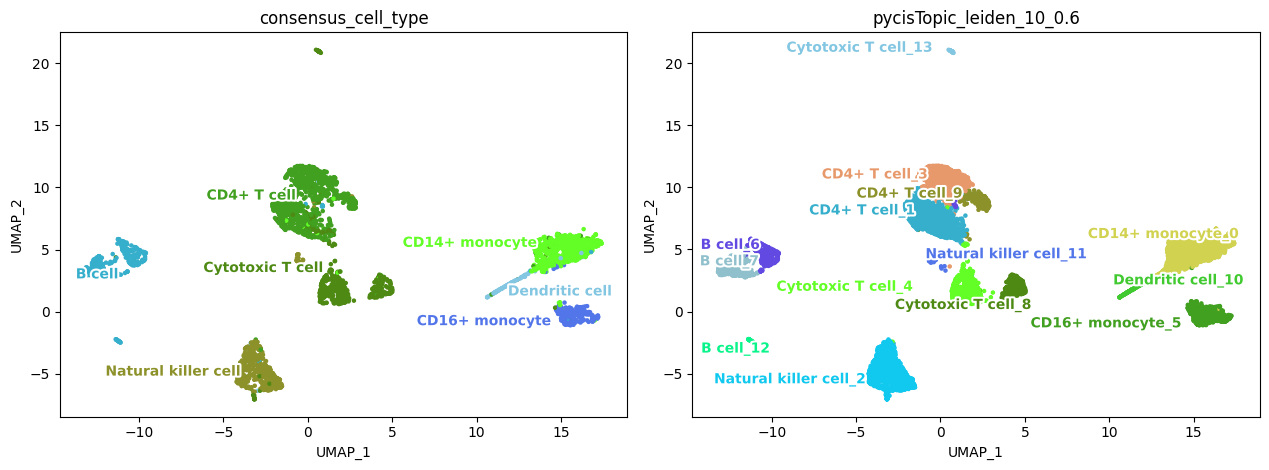

In [30]:
plot_metadata(
    cistopic_obj,
    reduction_name='UMAP',
    variables=['consensus_cell_type', 'pycisTopic_leiden_10_0.6'],
    target='cell', 
    num_columns=2,
    text_size=10,
    dot_size=5)

Now we have the Leiden annotation modified to our actually annotation with finegrained differences between the orginal annotation.

In [31]:
cistopic_obj.cell_data['pycisTopic_leiden_10_0.6'].value_counts(dropna = False)

CD14+ monocyte_0          1683
CD4+ T cell_1             1321
Natural killer cell_2     1243
CD4+ T cell_3             1092
Cytotoxic T cell_4         732
CD16+ monocyte_5           662
B cell_6                   440
B cell_7                   436
Cytotoxic T cell_8         393
CD4+ T cell_9              256
Dendritic cell_10          216
Natural killer cell_11      79
B cell_12                   68
Cytotoxic T cell_13         54
Name: pycisTopic_leiden_10_0.6, dtype: int64

In [32]:
sample_counts = cistopic_obj.cell_data['pycisTopic_leiden_10_0.6'].value_counts().to_dict()
print(sample_counts)

{'CD14+ monocyte_0': 1683, 'CD4+ T cell_1': 1321, 'Natural killer cell_2': 1243, 'CD4+ T cell_3': 1092, 'Cytotoxic T cell_4': 732, 'CD16+ monocyte_5': 662, 'B cell_6': 440, 'B cell_7': 436, 'Cytotoxic T cell_8': 393, 'CD4+ T cell_9': 256, 'Dendritic cell_10': 216, 'Natural killer cell_11': 79, 'B cell_12': 68, 'Cytotoxic T cell_13': 54}


It's best practice to clean up the annotations and have no white space nor extras like '+, /, -, ...'. This could give problems for downstream analysis. We make a dictionary to choose how we name each cell type.

In [33]:
cistopic_obj.cell_data['pycistopic_cell_type'] = (
    cistopic_obj.cell_data['pycisTopic_leiden_10_0.6']
    .str.replace('+', '_pos', regex=False)
    .str.replace(' ', '-', regex=False)
)

Now we see a new column with the `pycistopic_cell_type` annotations to use downstream.

In [34]:
cistopic_obj.cell_data

,pdf_values_for_tss_enrichment,duplication_ratio,cisTopic_nr_acc,log10_total_fragments_count,pdf_values_for_duplication_ratio,cisTopic_nr_frag,cisTopic_log_nr_acc,pycisTopic_leiden_10_0.6,barcode,nucleosome_signal,...,sample_id,unique_fragments_in_peaks_count,duplication_count,tss_enrichment,fraction_of_fragments_in_peaks,total_fragments_count,log10_unique_fragments_count,pycisTopic_leiden_10_3,consensus_cell_type,pycistopic_cell_type
GTATAGCTGGACACCC-CNA_10xv2_1___CNA_10xv2_1,0.002986,0.581974,13523,4.716863,0.347629,16664,4.131073,CD16+ monocyte_5,GTATAGCTGGACACCC,0.399101,...,CNA_10xv2_1,16499,30322,14.988045,0.757530,52102,4.338078,CD16+ monocyte_20,CD16+ monocyte,CD16_pos-monocyte_5
CGCACTTACCAATAGA-CNA_10xv2_1___CNA_10xv2_1,0.004606,0.409524,9769,4.382539,0.036925,11443,3.98985,CD14+ monocyte_0,CGCACTTACCAATAGA,0.337660,...,CNA_10xv2_1,11316,9881,18.155290,0.794272,24128,4.153754,CD14+ monocyte_5,CD14+ monocyte,CD14_pos-monocyte_0
GTTCCCATGACCGTGC-CNA_10xv2_1___CNA_10xv2_1,0.001465,0.671337,12815,4.868450,0.197593,19315,4.107719,Natural killer cell_2,GTTCCCATGACCGTGC,0.315032,...,CNA_10xv2_1,19085,49589,28.813296,0.786135,73866,4.385213,Natural killer cell_8,Cytotoxic T cell,Natural-killer-cell_2
CTGCACGGATGTCACA-CNA_10xv2_1___CNA_10xv2_1,0.004214,0.486085,9242,4.421801,0.146587,10646,3.965766,CD16+ monocyte_5,CTGCACGGATGTCACA,0.322734,...,CNA_10xv2_1,10548,12838,17.049868,0.777131,26411,4.132708,CD16+ monocyte_1,CD16+ monocyte,CD16_pos-monocyte_5
AGCCGGTACAGGTGCA-CNA_10xv2_1___CNA_10xv2_1,0.004779,0.603648,10166,4.619834,0.499333,12141,4.00715,CD16+ monocyte_5,AGCCGGTACAGGTGCA,0.505455,...,CNA_10xv2_1,11990,25154,18.387468,0.725963,41670,4.217931,CD16+ monocyte_35,CD16+ monocyte,CD16_pos-monocyte_5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
AACGCGAGATTCAGTG-CNA_10xv2_2___CNA_10xv2_2,0.000047,0.379687,1327,3.439017,0.029771,1428,3.122871,Natural killer cell_2,AACGCGAGATTCAGTG,0.154114,...,CNA_10xv2_2,1417,1043,57.044970,0.831573,2747,3.231724,Natural killer cell_29,NaN,Natural-killer-cell_2
ATTTCGACTAAGGCCA-CNA_10xv2_2___CNA_10xv2_2,0.000393,0.316518,1049,3.305996,0.024201,1079,3.020775,CD14+ monocyte_0,ATTTCGACTAAGGCCA,0.419565,...,CNA_10xv2_2,1067,640,20.776206,0.772069,2022,3.140822,CD14+ monocyte_5,NaN,CD14_pos-monocyte_0
ATCGCAAACCTACTCC-CNA_10xv2_2___CNA_10xv2_2,0.000406,0.599724,1173,3.704579,0.014657,1317,3.069298,CD16+ monocyte_5,ATCGCAAACCTACTCC,0.341944,...,CNA_10xv2_2,1308,3037,20.655151,0.645289,5064,3.307068,CD16+ monocyte_35,NaN,CD16_pos-monocyte_5
TGGTAGGGAGAACCTT-CNA_10xv2_2___CNA_10xv2_2,0.000371,0.713076,963,3.929674,0.004271,1151,2.983626,CD14+ monocyte_0,TGGTAGGGAGAACCTT,0.548128,...,CNA_10xv2_2,1140,6064,22.887597,0.467213,8504,3.387568,CD14+ monocyte_7,NaN,CD14_pos-monocyte_0


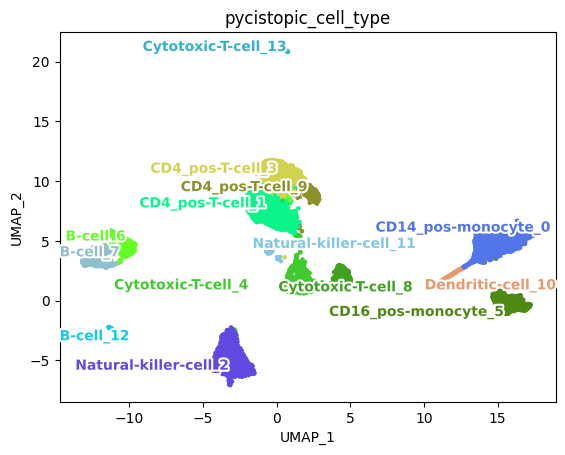

In [35]:
plot_metadata(
    cistopic_obj,
    reduction_name='UMAP',
    variables=['pycistopic_cell_type'],
    target='cell', 
    num_columns=1,
    text_size=10,
    dot_size=5)

In [12]:
#let's save the cistopic object with the annotations
out_dir = '/data/user/u0123819/cistopic_outs/' #adapt this to your own directory 

# pickle.dump(
    cistopic_obj,
    open(os.path.join(out_dir, "cistopic_obj_noDBL_annot.pkl"), "wb")
)

# 6. Downstream analyis

### Now let's explore the topics information

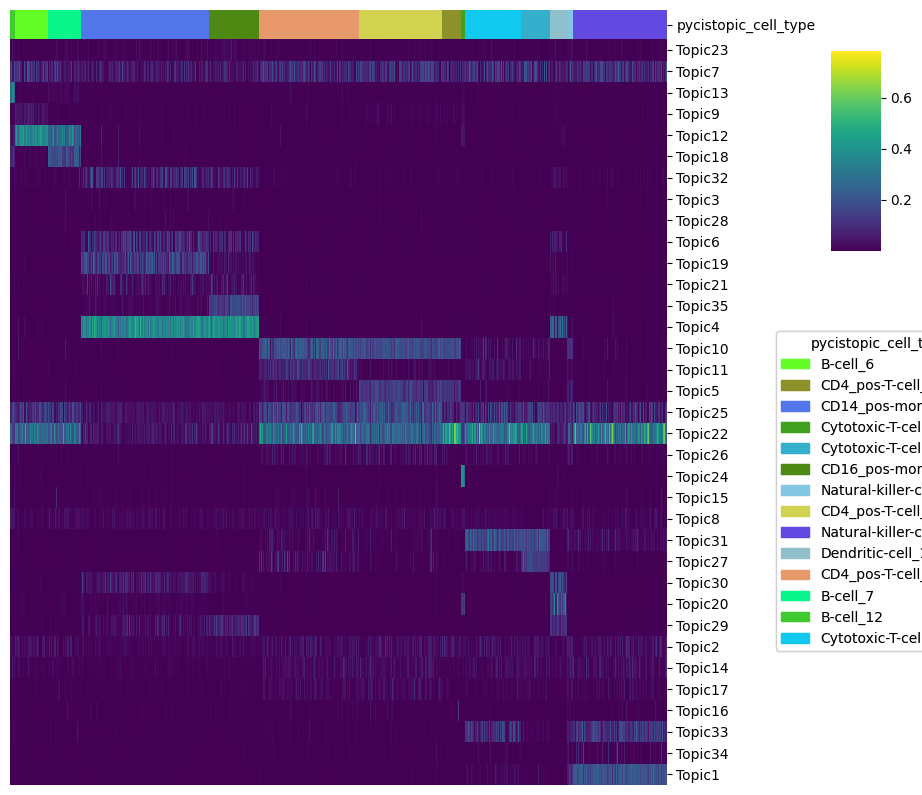

In [44]:
cell_topic_heatmap(
    cistopic_obj,
    variables = ['pycistopic_cell_type'],
    scale = False,
    legend_loc_x = 1.0,
    legend_loc_y = -1.2,
    legend_dist_y = -1,
    figsize = (10, 10)
)

We see that some topics are cell type specific. Thus, they contain a set of regions that are specific for that cell type. We can also visualize them on a UMAP/tSNE

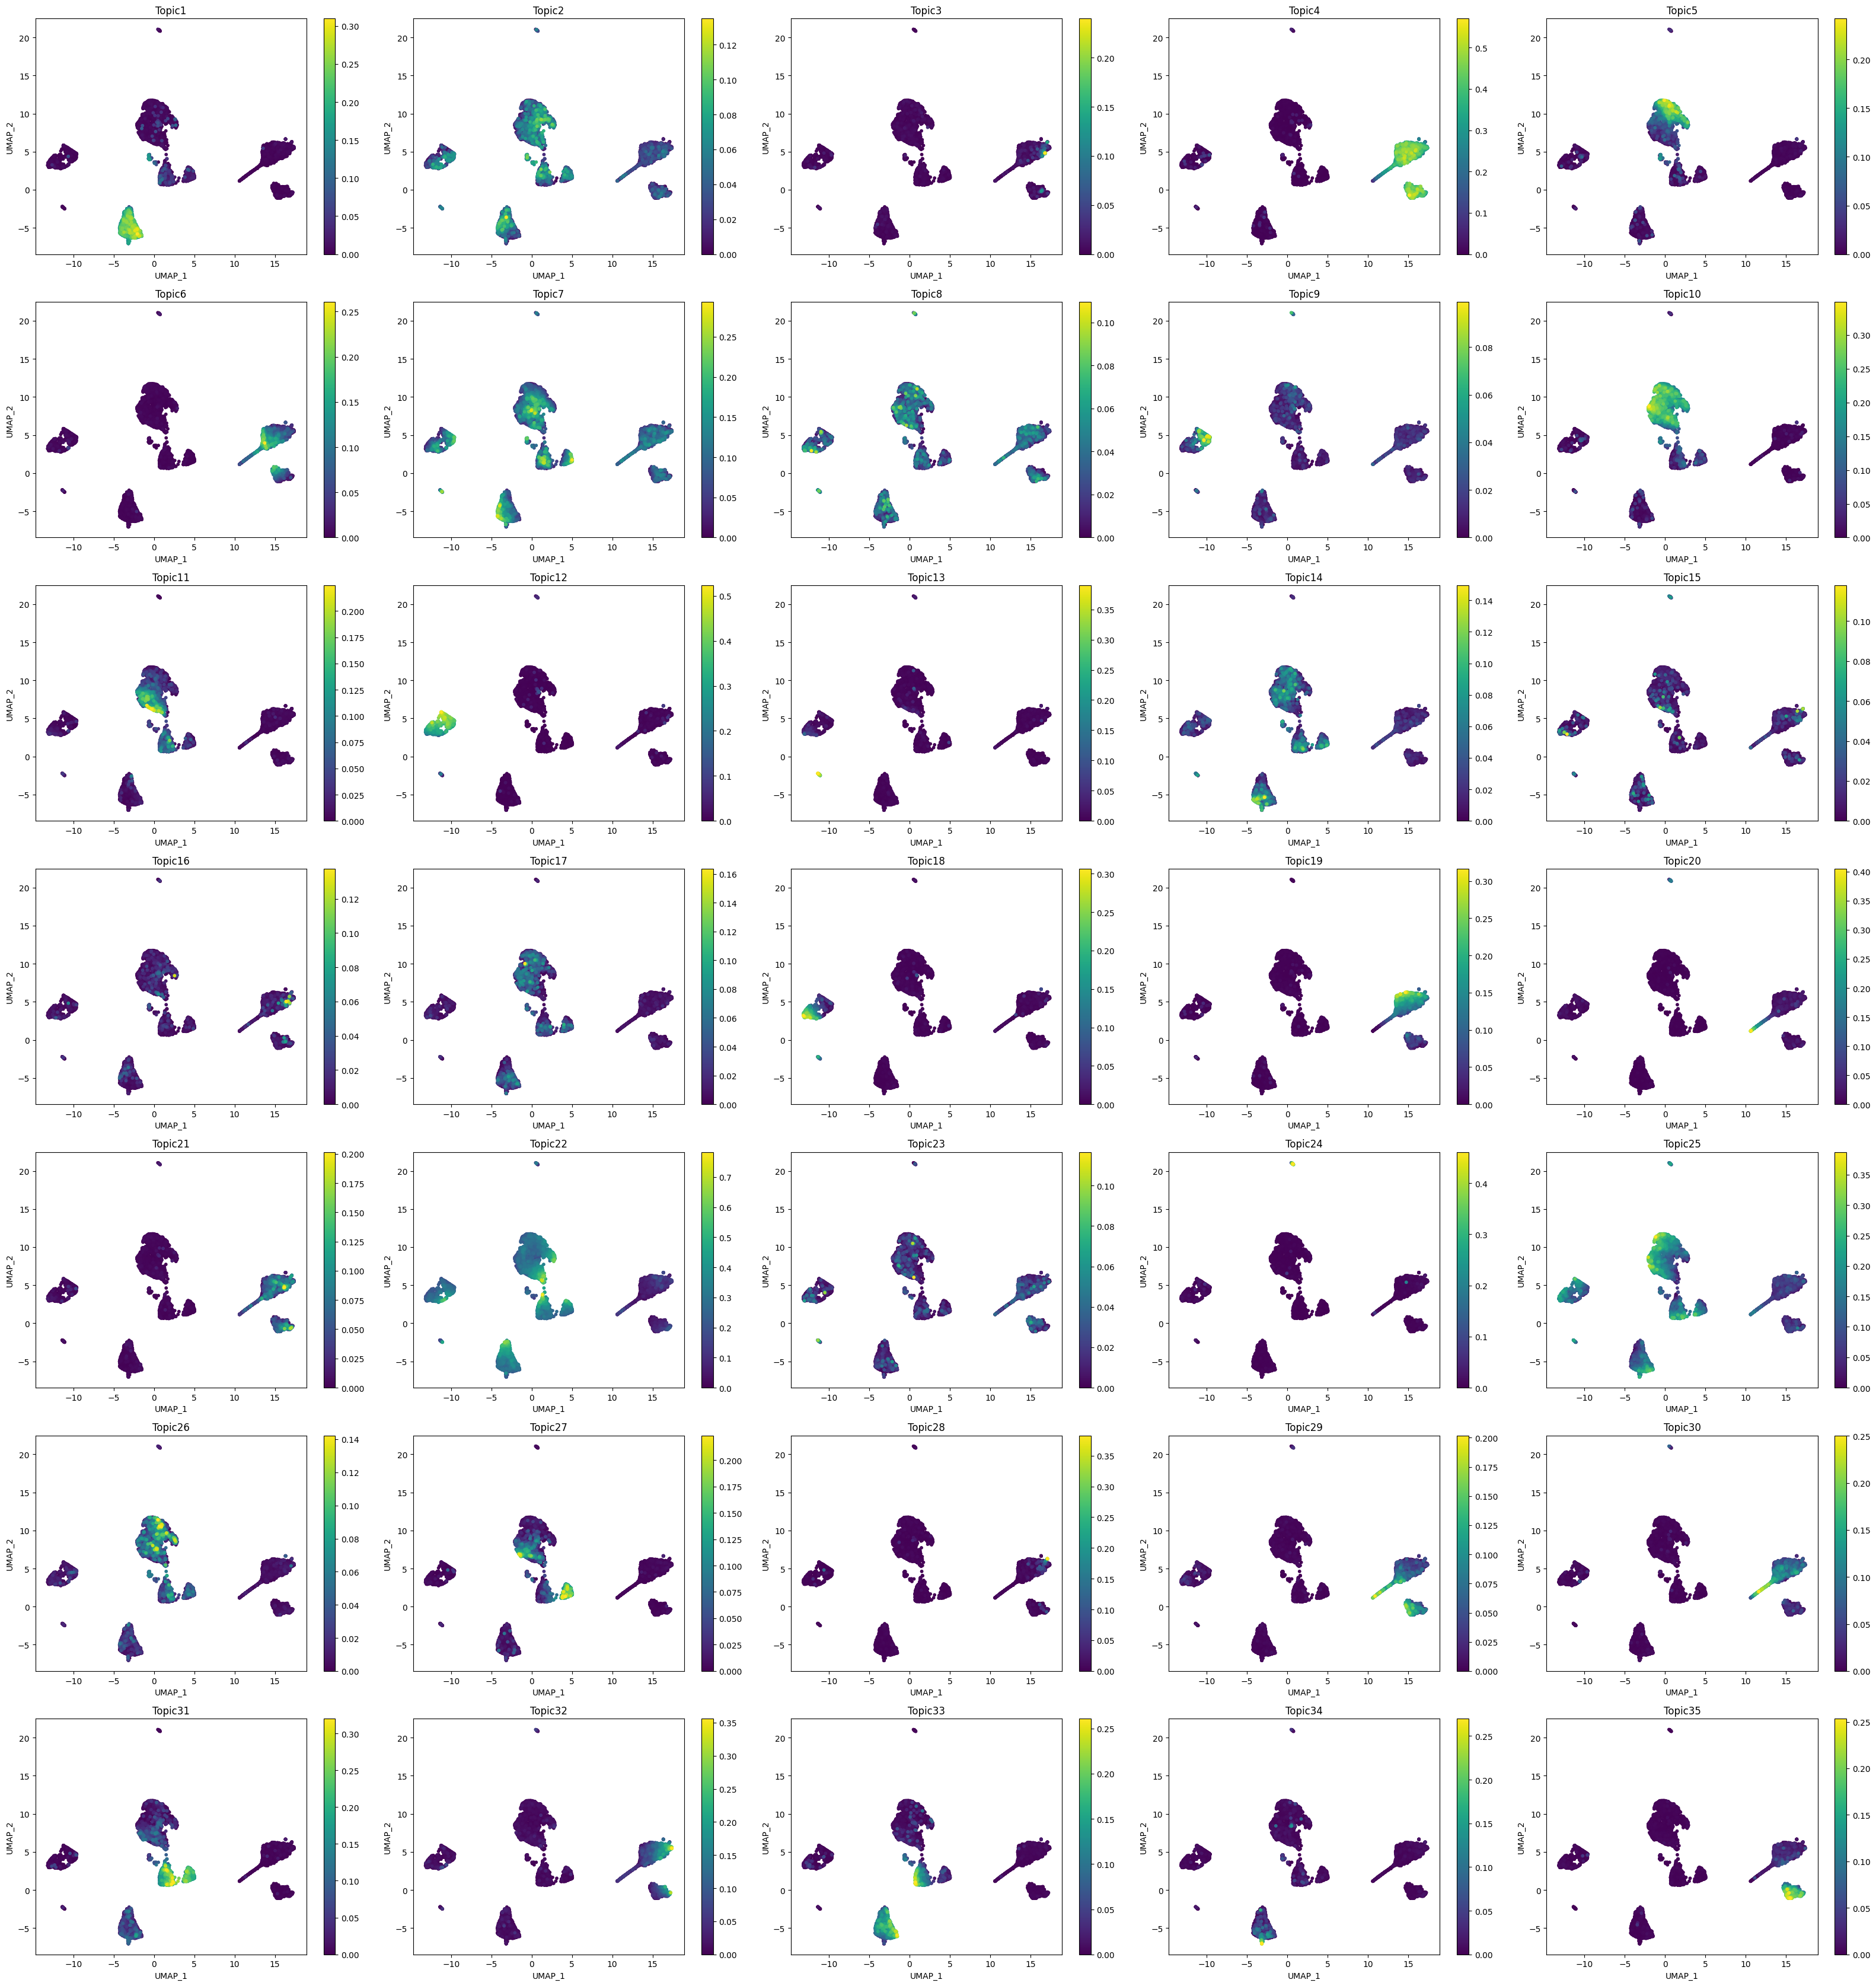

In [45]:
plot_topic(
    cistopic_obj,
    reduction_name = 'UMAP',
    target = 'cell',
    num_columns=5
)

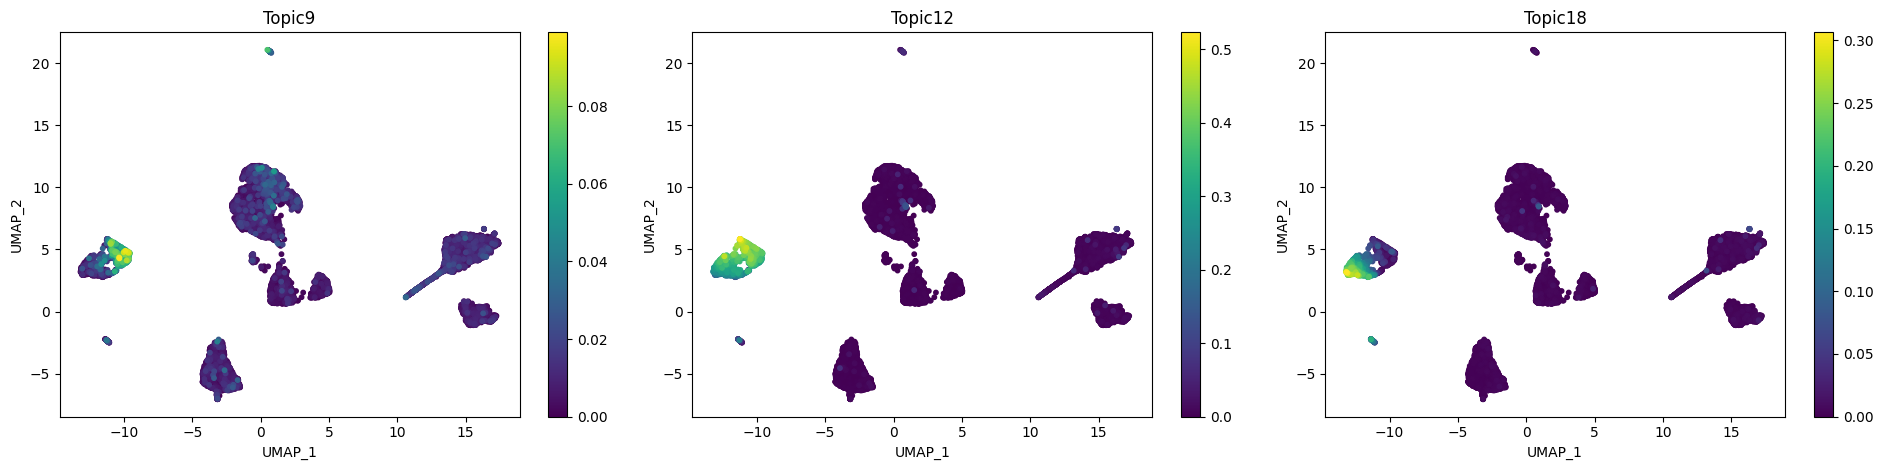

In [47]:
plot_topic(
    cistopic_obj,
    reduction_name = 'UMAP',
    target = 'cell',
    num_columns = 3,
    selected_topics = [9, 12, 18]
)

You can further explore top regions associated with topics and nearby genes following the tutorial:  
https://pycistopic.readthedocs.io/en/latest/notebooks/human_cerebellum.html#Topic-binarization-&-QC 

In [3]:
# in case you closed this notebook, reload the cistopic obj:
import pickle
infile = open('./cistopic_outs/cistopic_obj_noDBL_annot.pkl', 'rb')
cistopic_obj = pickle.load(infile)
infile.close()

# Differentially Accessible Regions (DARs) per cell type

To investigate the regions that are differentially accessible (thus specific) for a cell type, we run code to obtain the differentially accessible regions (DARs).

The first step is to impute the accessible regions from our cistopic object.

In [48]:
from pycisTopic.diff_features import (
    impute_accessibility,
    normalize_scores,
    find_highly_variable_features,
    find_diff_features
)
import numpy as np

In [49]:
imputed_acc_obj = impute_accessibility(
    cistopic_obj,
    selected_cells=None,
    selected_regions=None,
    scale_factor=10**6
)

2025-11-03 15:53:40,796 cisTopic     INFO     Imputing region accessibility
2025-11-03 15:53:40,797 cisTopic     INFO     Impute region accessibility for regions 0-20000
2025-11-03 15:53:43,812 cisTopic     INFO     Impute region accessibility for regions 20000-40000
2025-11-03 15:53:46,672 cisTopic     INFO     Impute region accessibility for regions 40000-60000
2025-11-03 15:53:49,442 cisTopic     INFO     Impute region accessibility for regions 60000-80000
2025-11-03 15:53:52,371 cisTopic     INFO     Impute region accessibility for regions 80000-100000
2025-11-03 15:53:55,158 cisTopic     INFO     Impute region accessibility for regions 100000-120000
2025-11-03 15:53:57,914 cisTopic     INFO     Impute region accessibility for regions 120000-140000
2025-11-03 15:54:00,941 cisTopic     INFO     Impute region accessibility for regions 140000-160000
2025-11-03 15:54:03,741 cisTopic     INFO     Impute region accessibility for regions 160000-180000
2025-11-03 15:54:07,098 cisTopic     

Next, we normalize them.

In [50]:
normalized_imputed_acc_obj = normalize_scores(imputed_acc_obj, scale_factor=10**4)

2025-11-03 15:54:37,284 cisTopic     INFO     Normalizing imputed data
2025-11-03 15:56:44,634 cisTopic     INFO     Done!


Then, we also calcuate the regions that are highly variable between cells based on the normalized imputed accessibility. This might take a few minutes.

2025-11-03 15:56:44,641 cisTopic     INFO     Calculating mean
2025-11-03 15:56:47,146 cisTopic     INFO     Calculating variance


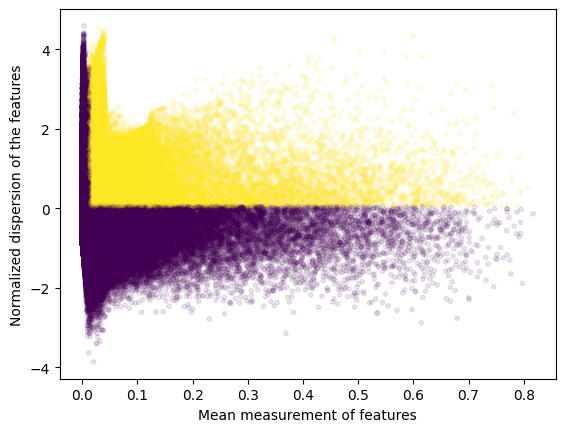

2025-11-03 15:59:00,108 cisTopic     INFO     Done!


In [51]:
variable_regions = find_highly_variable_features(
    normalized_imputed_acc_obj,
    min_disp = 0.05,
    min_mean = 0.0125,
    max_mean = 3,
    max_disp = np.inf,
    n_bins=20,
    n_top_features=None,
    plot=True
)

In [53]:
len(variable_regions)

58786

Our data should have 58786 high variable regions.

Lastly, we generate a dictonary of the regions "marking" a cell type, the markers_dict. For this we give the variable we want to group the cell into (aka `pycistopic_cell_type`). This might take up to 5 minutes.

In [54]:
markers_dict= find_diff_features(
    cistopic_obj,
    imputed_acc_obj,
    variable='pycistopic_cell_type',
    var_features=variable_regions,
    contrasts=None,
    adjpval_thr=0.05,
    log2fc_thr=np.log2(1.5),
    n_cpu=2,
    split_pattern = '-'
)

2025-11-03 16:00:14,760	INFO worker.py:1724 -- Started a local Ray instance.


2025-11-03 16:00:15,111 cisTopic     INFO     Subsetting data for B-cell_12 (68 of 8675)
2025-11-03 16:00:18,789 cisTopic     INFO     Computing p-value for B-cell_12


(get_wilcox_test_pvalues_ray pid=1996475) /data/teachers/software/miniforge3/envs/pycisTopic/lib/python3.11/site-packages/ray/_private/pydantic_compat.py:2: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
(get_wilcox_test_pvalues_ray pid=1996475)   from pkg_resources import packaging


2025-11-03 16:00:31,323 cisTopic     INFO     Computing log2FC for B-cell_12
2025-11-03 16:00:33,361 cisTopic     INFO     B-cell_12 done!
2025-11-03 16:00:33,504 cisTopic     INFO     Subsetting data for B-cell_6 (440 of 8675)
2025-11-03 16:00:34,171 cisTopic     INFO     Computing p-value for B-cell_6
2025-11-03 16:00:45,991 cisTopic     INFO     Computing log2FC for B-cell_6
2025-11-03 16:00:46,074 cisTopic     INFO     B-cell_6 done!
2025-11-03 16:00:46,223 cisTopic     INFO     Subsetting data for B-cell_7 (436 of 8675)
2025-11-03 16:00:46,485 cisTopic     INFO     Computing p-value for B-cell_7
2025-11-03 16:00:58,191 cisTopic     INFO     Computing log2FC for B-cell_7
2025-11-03 16:00:58,272 cisTopic     INFO     B-cell_7 done!
2025-11-03 16:00:58,416 cisTopic     INFO     Subsetting data for CD14_pos-monocyte_0 (1683 of 8675)
2025-11-03 16:00:58,639 cisTopic     INFO     Computing p-value for CD14_pos-monocyte_0
2025-11-03 16:01:10,714 cisTopic     INFO     Computing log2FC for

(get_wilcox_test_pvalues_ray pid=1996476) /data/teachers/software/miniforge3/envs/pycisTopic/lib/python3.11/site-packages/ray/_private/pydantic_compat.py:2: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
(get_wilcox_test_pvalues_ray pid=1996476)   from pkg_resources import packaging


In [55]:
print("Number of DARs found:")
print("---------------------")
for x in markers_dict:
    print(f"  {x}: {len(markers_dict[x])}")

Number of DARs found:
---------------------
  B-cell_12: 9865
  B-cell_6: 11470
  B-cell_7: 12984
  CD14_pos-monocyte_0: 29060
  CD16_pos-monocyte_5: 27375
  CD4_pos-T-cell_1: 11245
  CD4_pos-T-cell_3: 10819
  CD4_pos-T-cell_9: 9233
  Cytotoxic-T-cell_13: 12254
  Cytotoxic-T-cell_4: 10344
  Cytotoxic-T-cell_8: 10039
  Dendritic-cell_10: 25508
  Natural-killer-cell_11: 13927
  Natural-killer-cell_2: 9558


In [56]:
#let's save the markersdict
pickle.dump(
    markers_dict,
    open(os.path.join(out_dir, "markers_dict.pkl"), "wb")
)

We can also plot region accessibility onto the cell-topic UMAP. For example, let’s check how the best DARs for some cell types look like. The plotting function might take several minutes to run.

In [57]:
print(cistopic_obj.cell_data['pycistopic_cell_type'].unique())

['CD16_pos-monocyte_5' 'CD14_pos-monocyte_0' 'Natural-killer-cell_2'
 'Dendritic-cell_10' 'CD4_pos-T-cell_3' 'CD4_pos-T-cell_1'
 'Cytotoxic-T-cell_8' 'Cytotoxic-T-cell_4' 'B-cell_6' 'B-cell_7'
 'B-cell_12' 'Cytotoxic-T-cell_13' 'CD4_pos-T-cell_9'
 'Natural-killer-cell_11']


In [59]:
markers_dict['B-cell_6'].head()

,Log2FC,Adjusted_pval,Contrast
chr9:37251512-37252012,4.624007,3.662754e-262,B-cell_6
chr7:143015029-143015529,4.612480,1.007315e-261,B-cell_6
chr18:32902517-32903017,4.611855,1.007315e-261,B-cell_6
chr8:56699063-56699563,4.610385,9.757447e-262,B-cell_6
chr2:60873298-60873798,4.609115,3.103289e-262,B-cell_6


In [60]:
from pycisTopic.clust_vis import plot_imputed_features

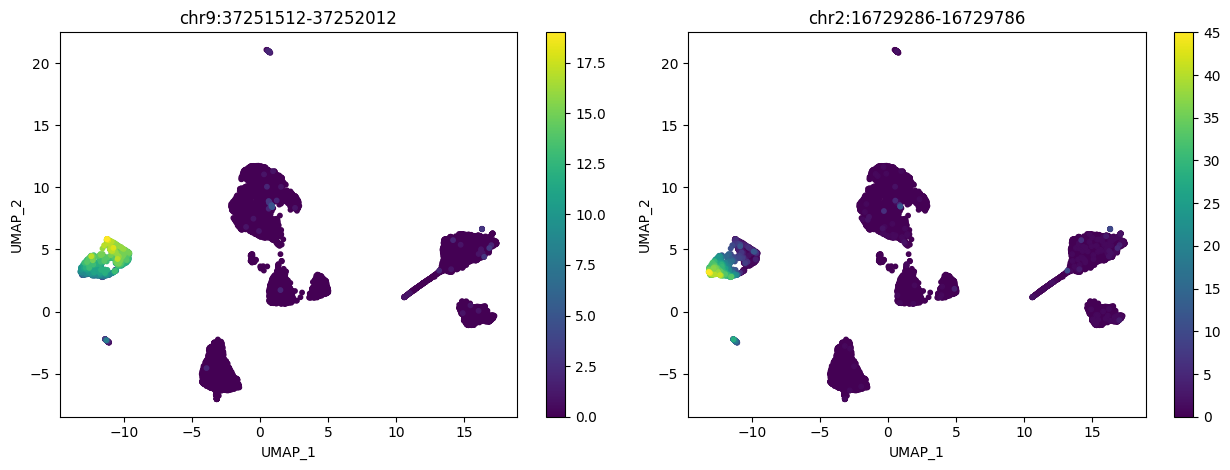

In [62]:
plot_imputed_features(
    cistopic_obj,
    reduction_name='UMAP',
    imputed_data=imputed_acc_obj,
    features=[markers_dict[x].index.tolist()[0] for x in ['B-cell_6', 'B-cell_7']],
    scale=False,
    num_columns=2
)

### Let's save the DARs to .bed files

In [63]:
from pycisTopic.utils import region_names_to_coordinates

os.makedirs(os.path.join(out_dir, "DARs_pycistopic_cell_type"), exist_ok = True)

In [64]:
for cell_type in markers_dict:
    ct = cell_type.replace(" ", "_")
    region_names_to_coordinates(
        markers_dict[cell_type].index
    ).sort_values(
        ["Chromosome", "Start", "End"]
    ).to_csv(
        os.path.join(out_dir, "DARs_pycistopic_cell_type", f"{ct}.bed"),
        sep = "\t",
        header = False, index = False
    )

# Coverage tracks per cell type

In [65]:
cistopic_obj.path_to_fragments

{'CNA_10xv2_1': '/data/teachers/data/scATAC/data_tutorial/CNA_10xv2_1.FULL.fragments.tsv.gz',
 'CNA_10xv2_2': '/data/teachers/data/scATAC/data_tutorial/CNA_10xv2_2.FULL.fragments.tsv.gz'}

In [9]:
chromsizes = pd.read_table(
    "http://hgdownload.cse.ucsc.edu/goldenPath/hg38/bigZips/hg38.chrom.sizes",
    header = None,
    names = ["Chromosome", "End"]
)
chromsizes.insert(1, "Start", 0)
chromsizes.head()


,Chromosome,Start,End
0,chr1,0,248956422
1,chr2,0,242193529
2,chr3,0,198295559
3,chr4,0,190214555
4,chr5,0,181538259


In [10]:
cistopic_obj.path_to_fragments

{'CNA_10xv2_1': '/data/teachers/data/scATAC/data_tutorial/CNA_10xv2_1.FULL.fragments.tsv.gz',
 'CNA_10xv2_2': '/data/teachers/data/scATAC/data_tutorial/CNA_10xv2_2.FULL.fragments.tsv.gz'}

Now we can create the coverage tracks per cell type (takes up to 8 minutes). We can look at the bigwig files in IGV and use them for machine learning purposes.

In [14]:
from pycisTopic.pseudobulk_peak_calling import export_pseudobulk
os.makedirs(os.path.join(out_dir, "consensus_peak_calling"), exist_ok = True)
os.makedirs(os.path.join(out_dir, "consensus_peak_calling/pseudobulk_bed_files"), exist_ok = True)
os.makedirs(os.path.join(out_dir, "consensus_peak_calling/pseudobulk_bw_files"), exist_ok = True)


bw_paths, bed_paths = export_pseudobulk(
    input_data =  cistopic_obj.cell_data,
    variable = "pycistopic_cell_type",
    sample_id_col = "sample_id",
    chromsizes = chromsizes,
    bed_path = os.path.join(out_dir, "consensus_peak_calling/pseudobulk_bed_files"),
    bigwig_path = os.path.join(out_dir, "consensus_peak_calling/pseudobulk_bw_files"),
    path_to_fragments = cistopic_obj.path_to_fragments,
    n_cpu = 1,
    normalize_bigwig = True,
    temp_dir = tempfile.mkdtemp(),
    split_pattern = "-"
)

2025-11-03 17:22:49,055 cisTopic     INFO     Splitting fragments by cell type.


IOStream.flush timed out


2025-11-03 17:25:34,240 cisTopic     INFO     generating bigwig files
2025-11-03 17:25:53,622 cisTopic     INFO     /data/user/u0123819/cistopic_outs/consensus_peak_calling/pseudobulk_bw_files/CD16_pos-monocyte_5.bw done!
2025-11-03 17:26:31,378 cisTopic     INFO     /data/user/u0123819/cistopic_outs/consensus_peak_calling/pseudobulk_bw_files/CD14_pos-monocyte_0.bw done!
2025-11-03 17:26:54,163 cisTopic     INFO     /data/user/u0123819/cistopic_outs/consensus_peak_calling/pseudobulk_bw_files/Natural-killer-cell_2.bw done!
2025-11-03 17:27:07,929 cisTopic     INFO     /data/user/u0123819/cistopic_outs/consensus_peak_calling/pseudobulk_bw_files/Dendritic-cell_10.bw done!
2025-11-03 17:27:32,078 cisTopic     INFO     /data/user/u0123819/cistopic_outs/consensus_peak_calling/pseudobulk_bw_files/CD4_pos-T-cell_3.bw done!
2025-11-03 17:27:56,162 cisTopic     INFO     /data/user/u0123819/cistopic_outs/consensus_peak_calling/pseudobulk_bw_files/CD4_pos-T-cell_1.bw done!
2025-11-03 17:28:09,909 